# Dogri ⇄ Punjabi — plain, proper LoRA fine-tuning of IndicTrans2-1B

**Two fully independent adapters on the 1B model: `doi2pan` and `pan2doi`.**

This notebook is deliberately *only* supervised fine-tuning on your own parallel Dogri–Punjabi data. Removed from the previous version: BPCC pivot pairs, IndicCorp monolingual data, back-translation / stage 2, asymmetric per-part ranks, adapter averaging, MBR decoding.

| Step | What happens |
|---|---|
| Data | Rule filter → LaBSE semantic filter → 90/5/5 split (no duplicates across splits) |
| Model | `ai4bharat/indictrans2-indic-indic-1B`, frozen, fp16/bf16 |
| Adapter | One LoRA adapter per direction on **all** attention (self, cross) + FFN projections, trained from scratch, nothing shared |
| Training | Full training split (no subsampling), cosine LR, warm-up, label smoothing, AdamW, grad clipping, per-epoch validation chrF++, early stopping, best-adapter saving, crash-safe resume |
| Evaluation | Test set used **once**, at the very end, vs. the untouched base model |

All hyper-parameters live in **one place (cell 2)** and are set **per direction** (`HP["doi2pan"]`, `HP["pan2doi"]`) so each adapter can be tuned separately without touching code.


In [1]:
# =============================================================================
# CELL 1 — INSTALL DEPENDENCIES  (same pins as before)
# =============================================================================
!pip install -q uv

!uv pip install --system \
    "transformers<4.40.0" \
    "peft<=0.10.0" \
    "accelerate>=0.28.0,<0.30.0" \
    datasets \
    sacrebleu \
    sentencepiece \
    einops \
    pandas \
    numpy \
    scikit-learn \
    tqdm \
    sentence-transformers

!uv pip install --system "git+https://github.com/VarunGumma/IndicTransToolkit.git"

import torch, transformers, peft, sacrebleu
print("PyTorch      :", torch.__version__)
print("Transformers :", transformers.__version__)
print("PEFT         :", peft.__version__)
print("SacreBLEU    :", sacrebleu.__version__)
if torch.cuda.is_available():
    print("GPU          :", torch.cuda.get_device_name(0), "| count:", torch.cuda.device_count())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.6/20.6 MB 78.5 MB/s eta 0:00:00
Using Python 3.13.15 environment at: /usr
Resolved 83 packages in 891ms
Prepared 8 packages in 279ms
Uninstalled 6 packages in 967ms
Installed 8 packages in 47ms
 - accelerate==1.14.0
 + accelerate==0.29.3
 - huggingface-hub==1.29.0
 + huggingface-hub==0.36.2
 - peft==0.20.0
 + peft==0.10.0
 + portalocker==4.4.0
 + sacrebleu==2.6.0
 - sentence-transformers==5.7.0
 + sentence-transformers==3.1.1
 - tokenizers==0.23.1
 + tokenizers==0.15.2
 - transformers==5.16.1
 + transformers==4.39.3
Using Python 3.13.15 environment at: /usr
Resolved 56 packages in 637ms
Prepared 7 packages in 10.26s
Installed 7 packages in 7ms
 + indic-nlp-library-itt==0.1.1
 + indictranstoolkit==1.1.1 (from git+https://github.com/VarunGumma/IndicTransToolkit.git@3efb8418d0721b4ce267c2b3586899d313191357)
 + morfessor==2.0.6
 + sacremoses==0.2.0
 + sphinx-argparse==0.6.1
 + sphinx-rtd-theme==3.1.0
 + sphinxcontrib-jquery==4.1
PyTorch      :

In [2]:
# =============================================================================
# CELL 2 — GLOBAL CONFIGURATION  (Dogri <-> Punjabi, IndicTrans2-1B, plain LoRA fine-tuning)
# =============================================================================
import os, gc, re, json, glob, shutil, random, time, unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import torch

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# T4 / P100 have no bf16 -> fp16 there; bf16 only on Ampere+.
_cc_major = torch.cuda.get_device_capability(0)[0] if torch.cuda.is_available() else 0
MODEL_DTYPE = torch.bfloat16 if (torch.cuda.is_available() and _cc_major >= 8
                                 and torch.cuda.is_bf16_supported()) else torch.float16
print("Device:", DEVICE, "| dtype:", MODEL_DTYPE)

QUICK_TEST_MODE = False        # True -> tiny smoke test of the whole pipeline (500 pairs, 1 epoch)

# ---------------------------------------------------------------- base model (1B)
MODEL_NAME = "ai4bharat/indictrans2-indic-indic-1B"
MODEL_TAG = "1B"

LANG_TAG = {"doi": "doi_Deva", "pan": "pan_Guru"}
DIRECTIONS = ["doi2pan", "pan2doi"]
_SPEC = {"doi2pan": ("doi", "pan"), "pan2doi": ("pan", "doi")}

# ---------------------------------------------------------------- data quality / split
SIM_FLOOR = 0.55               # LaBSE floor
DROP_BOTTOM_PCT = 5            # ... or drop the bottom 5 %, whichever threshold is higher
VAL_FRAC = 0.05
TEST_FRAC = 0.05
VALIDATION_SELECTION_SIZE = 1000   # fixed validation subset used for every epoch-level decision
MIN_WORDS, MAX_WORDS, MAX_LEN_RATIO = 2, 120, 3.0
MAX_LENGTH = 256               # max tokens (src and tgt); longer pairs are dropped, not truncated

# ---------------------------------------------------------------- LoRA architecture (identical *recipe* per direction,
#                                                                 but every direction gets its OWN adapter weights)
# IndicTrans2 linear layers: q/k/v/out projections (encoder self-attn, decoder self-attn, decoder cross-attn) + fc1/fc2 FFN
LORA_TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "out_proj", "fc1", "fc2"]
LORA_BIAS = "none"
USE_RSLORA = False             # leave False; True rescales alpha/sqrt(r) (needs peft >= 0.7)

# ---------------------------------------------------------------- training hyper-parameters (PER DIRECTION)
HP_COMMON = dict(
    # --- LoRA
    lora_r=96,
    lora_alpha=128,
    lora_dropout=0.1,
    # --- optimisation
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_ratio=0.05,
    weight_decay=0.01,
    adam_beta1=0.9,
    adam_beta2=0.999,
    adam_epsilon=1e-8,
    max_grad_norm=1.0,
    label_smoothing=0.1,
    optim="adamw_torch",
    # --- schedule / batching
    num_epochs=5,
    per_device_batch=8,
    grad_accum=2,                  # effective batch = per_device_batch x grad_accum x n_gpus
    group_by_length=True,
    # --- checkpointing / stopping
    early_stop_patience=2,         # epochs without val chrF++ improvement
    save_steps=500,                # crash-safe mid-epoch checkpoints (resume)
    logging_steps=50,
    # --- validation decoding
    val_beams=4,
    # --- wall-clock guard: stop cleanly at the end of the epoch in which this budget is exceeded
    max_train_hours=None,          # e.g. 4.5 on Kaggle if you need both directions inside one 12h session
    # --- optional cap on training pairs (None = use the WHOLE training split)
    max_train_examples=None,
)
HP = {d: dict(HP_COMMON) for d in DIRECTIONS}
# Per-direction overrides go here, e.g.:
# HP["pan2doi"]["learning_rate"] = 1.5e-4

if QUICK_TEST_MODE:
    VALIDATION_SELECTION_SIZE = 50
    for d in DIRECTIONS:
        HP[d].update(num_epochs=1, save_steps=50, logging_steps=10)

# ---------------------------------------------------------------- final test decoding
TEST_BEAMS = 5
TEST_LENGTH_PENALTY = 1.0

# ---------------------------------------------------------------- paths
OUTPUT_DIR = Path("/kaggle/working/dogpun_indictrans2")
SPLIT_DIR = OUTPUT_DIR / "splits"
ADAPTER_ROOT = OUTPUT_DIR / f"adapters_{MODEL_TAG}"
RESULTS_DIR = OUTPUT_DIR / "results"
FINAL_DIR = OUTPUT_DIR / "final_adapters"
for d in [OUTPUT_DIR, SPLIT_DIR, ADAPTER_ROOT, RESULTS_DIR, FINAL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

DATASET_PATH = Path("/kaggle/input/datasets/rkstriker/setunlp")
FILE_MAP = {"doi": DATASET_PATH / "train-dogri.txt", "pan": DATASET_PATH / "train-punjabi.txt"}
for lang, fp in FILE_MAP.items():
    if not fp.exists():
        raise FileNotFoundError(f"Missing required data file: {fp}")
    print(f"{lang:>4s} -> {fp}")

# ---------------------------------------------------------------- Hugging Face auth
try:
    from kaggle_secrets import UserSecretsClient
    from huggingface_hub import login
    HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
    login(token=HF_TOKEN)
except Exception:
    HF_TOKEN = os.getenv("HF_TOKEN", None)

print("\nModel:", MODEL_NAME)
for d in DIRECTIONS:
    print(f"  {d}: {json.dumps(HP[d])}")

Device: cuda | dtype: torch.float16
 doi -> /kaggle/input/datasets/rkstriker/setunlp/train-dogri.txt
 pan -> /kaggle/input/datasets/rkstriker/setunlp/train-punjabi.txt

Model: ai4bharat/indictrans2-indic-indic-1B
  doi2pan: {"lora_r": 96, "lora_alpha": 128, "lora_dropout": 0.1, "learning_rate": 0.0002, "lr_scheduler_type": "cosine", "warmup_ratio": 0.05, "weight_decay": 0.01, "adam_beta1": 0.9, "adam_beta2": 0.999, "adam_epsilon": 1e-08, "max_grad_norm": 1.0, "label_smoothing": 0.1, "optim": "adamw_torch", "num_epochs": 5, "per_device_batch": 8, "grad_accum": 2, "group_by_length": true, "early_stop_patience": 2, "save_steps": 500, "logging_steps": 50, "val_beams": 4, "max_train_hours": null, "max_train_examples": null}
  pan2doi: {"lora_r": 96, "lora_alpha": 128, "lora_dropout": 0.1, "learning_rate": 0.0002, "lr_scheduler_type": "cosine", "warmup_ratio": 0.05, "weight_decay": 0.01, "adam_beta1": 0.9, "adam_beta2": 0.999, "adam_epsilon": 1e-08, "max_grad_norm": 1.0, "label_smoothing": 0

In [3]:
# =============================================================================
# CELL 3 — INGESTION, NORMALISATION & RULE-BASED FILTERING  (doi-pan only)
# =============================================================================
def load_raw(path):
    with open(path, encoding="utf-8") as f:
        return [line.rstrip("\n") for line in f]

raw = {lang: load_raw(p) for lang, p in FILE_MAP.items()}
for lang, lines in raw.items():
    print(f"{lang}: {len(lines):,} raw lines")
assert len(raw["doi"]) == len(raw["pan"]), "doi / pan files are not line-aligned!"

PURE_NOISE_RE = re.compile(r"[\u200b\u2060\ufeff]")
WATERMARK_EDGES_RE = re.compile(r"^[\u200c\u200d]+|[\u200c\u200d]+$")

def clean_text(s):
    s = PURE_NOISE_RE.sub("", s)
    s = WATERMARK_EDGES_RE.sub("", s)
    s = unicodedata.normalize("NFC", s)          # NFC, NOT NFKC (keeps nukta letters intact)
    return re.sub(r"\s+", " ", s).strip()

DEVA_RANGE = (0x0900, 0x097F)
GURM_RANGE = (0x0A00, 0x0A7F)

def is_valid_line(text, lang):
    letters = [c for c in text if c.isalpha()]
    if not letters:
        return False
    total = len(letters)
    deva = sum(1 for c in letters if DEVA_RANGE[0] <= ord(c) <= DEVA_RANGE[1])
    gurm = sum(1 for c in letters if GURM_RANGE[0] <= ord(c) <= GURM_RANGE[1])
    if lang == "pan":
        return deva / total <= 0.15 and gurm / total >= 0.25
    if lang == "doi":
        return deva / total >= 0.25
    return True

def keep_pair(a, b, lang_a, lang_b):
    if not a or not b or a == b:
        return False
    if not (is_valid_line(a, lang_a) and is_valid_line(b, lang_b)):
        return False
    na, nb = len(a.split()), len(b.split())
    if na < MIN_WORDS or nb < MIN_WORDS or na > MAX_WORDS or nb > MAX_WORDS:
        return False
    return max(na, nb) / min(na, nb) <= MAX_LEN_RATIO

def filter_parallel_pair(A, B, la, lb):
    out_a, out_b = [], []
    for a, b in zip(A, B):
        if keep_pair(a, b, la, lb):
            out_a.append(a); out_b.append(b)
    return out_a, out_b

clean_doi, clean_pan = filter_parallel_pair(
    [clean_text(x) for x in raw["doi"]], [clean_text(x) for x in raw["pan"]], "doi", "pan")

print(f"\ndoi-pan kept after rules: {len(clean_doi):,} / {len(raw['doi']):,}")
print("Sample:\n ", clean_doi[0], "\n ", clean_pan[0])

doi: 28,000 raw lines
pan: 28,000 raw lines

doi-pan kept after rules: 27,970 / 28,000
Sample:
  बीऽ गी घट्ट डुंह्गेआई च राहओ। 
  ਬੀਜਾਂ ਨੂੰ ਘੱਟ ਡੂੰਘਾਈ 'ਤੇ ਬੀਜੋ।


In [4]:
# =============================================================================
# CELL 4 — LaBSE SEMANTIC FILTER  (helpers are reused later for external data / BT)
# =============================================================================
DROPPED_DIR = SPLIT_DIR / "dropped_by_labse"
DROPPED_DIR.mkdir(parents=True, exist_ok=True)
_LABSE = None

def get_labse():
    global _LABSE
    if _LABSE is None:
        from sentence_transformers import SentenceTransformer
        _LABSE = SentenceTransformer("sentence-transformers/LaBSE", device=str(DEVICE))
    return _LABSE

def free_labse():
    global _LABSE
    _LABSE = None
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def labse_filter(src, tgt, name, fixed_floor=None):
    m = get_labse()
    kw = dict(batch_size=128, show_progress_bar=True, normalize_embeddings=True, convert_to_numpy=True)
    sims = (m.encode(src, **kw) * m.encode(tgt, **kw)).sum(axis=1)
    thr = fixed_floor if fixed_floor is not None else max(SIM_FLOOR, float(np.percentile(sims, DROP_BOTTOM_PCT)))
    keep = sims >= thr
    print(f"[{name}] sim min={sims.min():.3f} median={np.median(sims):.3f} | threshold={thr:.3f} "
          f"| kept {int(keep.sum()):,}, dropped {int((~keep).sum()):,}")
    pd.DataFrame({"src": [s for s, k in zip(src, keep) if not k],
                  "tgt": [t for t, k in zip(tgt, keep) if not k],
                  "sim": sims[~keep]}).to_csv(DROPPED_DIR / f"{name}_dropped.csv", index=False)
    return [s for s, k in zip(src, keep) if k], [t for t, k in zip(tgt, keep) if k]

try:
    clean_doi, clean_pan = labse_filter(clean_doi, clean_pan, "doi_pan")
except Exception as e:
    print("!! LaBSE filtering skipped:", repr(e))

print(f"\nFinal doi-pan pairs: {len(clean_doi):,}")
free_labse()

modules.json:   0%|          | 0.00/461 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


config.json:   0%|          | 0.00/804 [00:00<?, ?B/s]

... (8 outputs left out)

2_Dense/model.safetensors:   0%|          | 0.00/2.36M [00:00<?, ?B/s]

Batches:   0%|          | 0/219 [00:00<?, ?it/s]

Batches:   0%|          | 0/219 [00:00<?, ?it/s]

[doi_pan] sim min=-0.033 median=0.716 | threshold=0.550 | kept 23,172, dropped 4,798

Final doi-pan pairs: 23,172


In [5]:
# =============================================================================
# CELL 5 — SPLIT  (90/5/5, duplicate-free across splits)
# =============================================================================
from sklearn.model_selection import train_test_split

def make_pair_df(a, b, na, nb):
    df = pd.DataFrame({na: a, nb: b}).drop_duplicates()
    df = df.drop_duplicates(subset=na).drop_duplicates(subset=nb)
    return df.reset_index(drop=True)

df_doi_pan = make_pair_df(clean_doi, clean_pan, "doi", "pan")

holdout = VAL_FRAC + TEST_FRAC
dp_train, _tmp = train_test_split(df_doi_pan, test_size=holdout, random_state=SEED, shuffle=True)
dp_val, dp_test = train_test_split(_tmp, test_size=TEST_FRAC / holdout, random_state=SEED + 1, shuffle=True)
dp_train, dp_val, dp_test = [x.reset_index(drop=True) for x in (dp_train, dp_val, dp_test)]

print(f"Dogri-Punjabi  total={len(df_doi_pan):,}  train={len(dp_train):,}  val={len(dp_val):,}  test={len(dp_test):,}")

dp_train.to_csv(SPLIT_DIR / "doi_pan_train.csv", index=False)
dp_val.to_csv(SPLIT_DIR / "doi_pan_val.csv", index=False)
dp_test.to_csv(SPLIT_DIR / "doi_pan_test.csv", index=False)

def make_direction_df(pair_df, s, t):
    return pd.DataFrame({"src_text": pair_df[s].tolist(), "tgt_text": pair_df[t].tolist()})

direction_data = {}
for d, (s, t) in _SPEC.items():
    full_val = make_direction_df(dp_val, s, t)
    sel = full_val.sample(n=min(VALIDATION_SELECTION_SIZE, len(full_val)), random_state=SEED).reset_index(drop=True)
    direction_data[d] = {
        "src_lang": LANG_TAG[s], "tgt_lang": LANG_TAG[t],
        "train": make_direction_df(dp_train, s, t),
        "val_selection": sel,
        "test": make_direction_df(dp_test, s, t),
    }
    sel.to_csv(SPLIT_DIR / f"{d}_val_selection_{len(sel)}.csv", index=False)
    print(f"{d}: train={len(direction_data[d]['train']):,} | val_selection={len(sel):,} | test={len(direction_data[d]['test']):,}")

Dogri-Punjabi  total=23,151  train=20,835  val=1,158  test=1,158
doi2pan: train=20,835 | val_selection=1,000 | test=1,158
pan2doi: train=20,835 | val_selection=1,000 | test=1,158


In [6]:
# =============================================================================
# CELL 6 — TOKENIZER, MODEL, COLLATOR, TOKENIZATION, EVALUATION HELPERS
# =============================================================================
import datasets as hf_datasets
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoConfig
from IndicTransToolkit import IndicProcessor

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True, token=HF_TOKEN)

_cfg = AutoConfig.from_pretrained(MODEL_NAME, trust_remote_code=True, token=HF_TOKEN)
PAD_ID = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else _cfg.pad_token_id
DECODER_START_ID = (_cfg.decoder_start_token_id if getattr(_cfg, "decoder_start_token_id", None) is not None
                    else tokenizer.eos_token_id)
print(f"pad={PAD_ID} decoder_start={DECODER_START_ID} eos={tokenizer.eos_token_id}")

ip_train = IndicProcessor(inference=False)
ip_eval = IndicProcessor(inference=True)

def load_base():
    return AutoModelForSeq2SeqLM.from_pretrained(
        MODEL_NAME, trust_remote_code=True, torch_dtype=MODEL_DTYPE, token=HF_TOKEN).to(DEVICE)

# ---------------------------------------------------------------- tokenization
def tokenize_batch(batch):
    inputs = tokenizer(batch["src_tagged"], truncation=True, max_length=MAX_LENGTH)
    labels = tokenizer(text_target=batch["tgt_text"], truncation=True, max_length=MAX_LENGTH)
    inputs["labels"] = labels["input_ids"]
    return inputs

def not_truncated(ex):
    return len(ex["input_ids"]) < MAX_LENGTH and len(ex["labels"]) < MAX_LENGTH

def make_tok_dataset(df, src_lang, tgt_lang, desc=""):
    # SOURCE and TARGET both go through IndicProcessor (-> Devanagari); the model only knows Devanagari.
    tagged_src = ip_train.preprocess_batch(df["src_text"].tolist(), src_lang=src_lang, tgt_lang=tgt_lang)
    tagged_tgt = ip_train.preprocess_batch(df["tgt_text"].tolist(), src_lang=tgt_lang, tgt_lang=None, is_target=True)
    ds = hf_datasets.Dataset.from_pandas(
        pd.DataFrame({"src_tagged": tagged_src, "tgt_text": tagged_tgt}), preserve_index=False)
    tok = ds.map(tokenize_batch, batched=True, remove_columns=["src_tagged", "tgt_text"], desc=f"Tokenizing {desc}")
    n0 = len(tok)
    tok = tok.filter(not_truncated)
    print(f"  {desc}: {len(tok):,} examples (dropped {n0 - len(tok):,} over-long)")
    return tok

class IndicSeq2SeqCollator:
    def __init__(self, tokenizer, pad_id, decoder_start_id, label_pad_id=-100, pad_to_multiple_of=8):
        self.tokenizer, self.pad_id, self.decoder_start_id = tokenizer, pad_id, decoder_start_id
        self.label_pad_id, self.m = label_pad_id, pad_to_multiple_of

    def __call__(self, features):
        labels = [list(f["labels"]) for f in features]
        enc = [{k: v for k, v in f.items() if k in ("input_ids", "attention_mask")} for f in features]
        batch = self.tokenizer.pad(enc, padding=True, pad_to_multiple_of=self.m, return_tensors="pt")
        L = max(len(l) for l in labels)
        L = ((L + self.m - 1) // self.m) * self.m
        lab = torch.full((len(labels), L), self.label_pad_id, dtype=torch.long)
        for i, l in enumerate(labels):
            lab[i, :len(l)] = torch.tensor(l, dtype=torch.long)
        dec = torch.full_like(lab, self.pad_id)
        dec[:, 1:] = lab[:, :-1]
        dec[:, 0] = self.decoder_start_id
        dec = dec.masked_fill(dec == self.label_pad_id, self.pad_id)
        batch["labels"], batch["decoder_input_ids"] = lab, dec
        return batch

collator = IndicSeq2SeqCollator(tokenizer, PAD_ID, DECODER_START_ID)

# ---------------------------------------------------------------- evaluation
CHRFPP = sacrebleu.CHRF(word_order=2)
try:
    sacrebleu.corpus_bleu(["test"], [["test"]], tokenize="flores200"); BLEU_TOKENIZE = "flores200"
except Exception:
    BLEU_TOKENIZE = "13a"
print("BLEU tokenizer:", BLEU_TOKENIZE)

def score(preds, refs):
    return {"BLEU": sacrebleu.corpus_bleu(preds, [refs], tokenize=BLEU_TOKENIZE).score,
            "chrF++": sacrebleu.corpus_chrf(preds, [refs], word_order=2).score}

@torch.inference_mode()
def translate(model, sentences, src_lang, tgt_lang, batch_size=16, num_beams=5,
              max_new_tokens=200, length_penalty=1.0):
    model.eval()
    out = []
    for i in tqdm(range(0, len(sentences), batch_size), desc=f"{src_lang[:3]}->{tgt_lang[:3]}", leave=False):
        batch = sentences[i:i + batch_size]
        processed = ip_eval.preprocess_batch(batch, src_lang=src_lang, tgt_lang=tgt_lang)
        inputs = tokenizer(processed, return_tensors="pt", padding=True, truncation=True,
                           max_length=MAX_LENGTH).to(DEVICE)
        gen = model.generate(**inputs, max_new_tokens=max_new_tokens, num_beams=num_beams,
                             length_penalty=length_penalty, early_stopping=True, use_cache=True)
        dec = tokenizer.batch_decode(gen, skip_special_tokens=True)
        out.extend([x.strip() for x in ip_eval.postprocess_batch(dec, lang=tgt_lang)])
    return out

def evaluate_validation_fast(model, validation_data, src_lang, tgt_lang, num_beams=4, **gen_kw):
    was_training = model.training
    preds = translate(model, validation_data["src_text"].tolist(), src_lang, tgt_lang,
                      num_beams=num_beams, **gen_kw)
    if was_training:
        model.train()
    s = score(preds, validation_data["tgt_text"].tolist())
    return {"bleu": s["BLEU"], "chrf": s["chrF++"]}

print("Helpers ready.")

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenization_indictrans.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-indic-indic-1B:
- tokenization_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


dict.SRC.json: 0.00B [00:00, ?B/s]

dict.TGT.json: 0.00B [00:00, ?B/s]

model.SRC:   0%|          | 0.00/3.26M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/96.0 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

configuration_indictrans.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-indic-indic-1B:
- configuration_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


pad=1 decoder_start=2 eos=2
BLEU tokenizer: flores200
Helpers ready.


In [7]:
# =============================================================================
# CELL 7 — TOKENIZE FULL TRAINING DATA, PRE-FLIGHT CHECKS, ROUND-TRIP CEILING, BASE-MODEL VALIDATION
# =============================================================================
print("Tokenizing training data (full split) ...")
train_tok = {}
for d in DIRECTIONS:
    info = direction_data[d]
    df = info["train"]
    cap = HP[d]["max_train_examples"]
    if QUICK_TEST_MODE:
        df = df.iloc[:500].copy()
    tok = make_tok_dataset(df, info["src_lang"], info["tgt_lang"], desc=f"{d} train")
    if cap is not None and len(tok) > cap:
        tok = tok.shuffle(seed=SEED).select(range(cap))
    train_tok[d] = tok

# ------------------------------------------------------------------ language / token sanity
for d in DIRECTIONS:
    info = direction_data[d]
    row = info["train"].iloc[:1]
    ex = train_tok[d][0]
    tgt_deva = ip_train.preprocess_batch(row["tgt_text"].tolist(), src_lang=info["tgt_lang"], tgt_lang=None, is_target=True)[0]
    deva = sum(1 for ch in tgt_deva if 0x0900 <= ord(ch) <= 0x097F)
    alpha = max(sum(1 for ch in tgt_deva if ch.isalpha()), 1)
    assert deva / alpha > 0.9, f"{d}: target is NOT Devanagari -> labels wrong"
    assert ex["labels"][-1] == tokenizer.eos_token_id, f"{d}: labels do not end with EOS"
    print(f"{d}: target Devanagari share {deva/alpha:.0%} | first src tokens {tokenizer.convert_ids_to_tokens(ex['input_ids'])[:5]}")

# ------------------------------------------------------------------ base model
base_model = load_base().eval()

print("\nPRE-FLIGHT (pretrained loss on the labels; healthy = 1-5):")
for d in DIRECTIONS:
    b = collator([train_tok[d][i] for i in range(16)])
    b = {k: v.to(DEVICE) for k, v in b.items()}
    with torch.no_grad(), torch.autocast(device_type="cuda", dtype=MODEL_DTYPE):
        loss = base_model(**b).loss.item()
    print(f"  {d}: {loss:.3f}")
    assert loss < 8, f"{d}: labels mis-wired (loss {loss:.2f})"

# ------------------------------------------------------------------ ROUND-TRIP CEILING (script conversion + tokenizer loss)
print("\nROUND-TRIP CEILING (chrF++ of the REFERENCE against itself after the pipeline; 100 = lossless):")
ROUNDTRIP = {}
for lang in ["pan", "doi"]:
    tag = LANG_TAG[lang]
    refs = dp_val[lang].tolist()[:1000]
    other = LANG_TAG["doi" if lang == "pan" else "pan"]
    deva = ip_train.preprocess_batch(refs, src_lang=tag, tgt_lang=None, is_target=True)
    ids = tokenizer(text_target=deva, truncation=True, max_length=MAX_LENGTH)["input_ids"]
    unk = tokenizer.unk_token_id
    unk_rate = sum(i.count(unk) for i in ids) / max(sum(len(i) for i in ids), 1)
    dec = tokenizer.batch_decode(ids, skip_special_tokens=True)
    ip_eval.preprocess_batch(refs, src_lang=other, tgt_lang=tag)     # refills placeholder state
    back = [x.strip() for x in ip_eval.postprocess_batch(dec, lang=tag)]
    sc = score(back, refs)
    ROUNDTRIP[lang] = sc
    print(f"  {lang}: chrF++={sc['chrF++']:.2f} BLEU={sc['BLEU']:.2f} | <unk> token rate={unk_rate:.4%}")

# ------------------------------------------------------------------ base validation (same fixed subset, same beams)
BASE_VAL = {}
print("\nBASE MODEL on fixed validation subset:")
for d in DIRECTIONS:
    info = direction_data[d]
    r = evaluate_validation_fast(base_model, info["val_selection"], info["src_lang"], info["tgt_lang"],
                                 num_beams=HP[d]["val_beams"])
    BASE_VAL[d] = r
    print(f"  {d}: BLEU={r['bleu']:.2f} chrF++={r['chrf']:.2f}")

del base_model
gc.collect(); torch.cuda.empty_cache()

Tokenizing training data (full split) ...


Tokenizing doi2pan train:   0%|          | 0/20835 [00:00<?, ? examples/s]

Filter:   0%|          | 0/20835 [00:00<?, ? examples/s]

  doi2pan train: 20,835 examples (dropped 0 over-long)


Tokenizing pan2doi train:   0%|          | 0/20835 [00:00<?, ? examples/s]

Filter:   0%|          | 0/20835 [00:00<?, ? examples/s]

... (6 outputs left out)

doi->pan:   0%|          | 0/63 [00:00<?, ?it/s]

  doi2pan: BLEU=45.26 chrF++=58.59


pan->doi:   0%|          | 0/63 [00:00<?, ?it/s]

  pan2doi: BLEU=38.66 chrF++=52.57


In [8]:
# =============================================================================
# CELL 8 — LoRA + TRAINING ENGINE  (one call = one independent adapter)
# =============================================================================
from transformers import Seq2SeqTrainingArguments, Seq2SeqTrainer, TrainerCallback
from peft import LoraConfig, get_peft_model, PeftModel

def build_lora_config(hp):
    kw = dict(r=hp["lora_r"], lora_alpha=hp["lora_alpha"], lora_dropout=hp["lora_dropout"],
              bias=LORA_BIAS, task_type="SEQ_2_SEQ_LM", target_modules=LORA_TARGET_MODULES)
    if USE_RSLORA:
        kw["use_rslora"] = True
    return LoraConfig(**kw)

def report_lora(peft_model):
    # confirm what was actually wrapped: per-part module counts
    counts = {}
    for n, m in peft_model.named_modules():
        if getattr(m, "lora_A", None) is not None and "default" in m.lora_A:
            if "encoder_attn" in n:            part = "dec cross-attn"
            elif "encoder.layers" in n:        part = "enc attn" if "self_attn" in n else "enc ffn"
            elif "decoder.layers" in n:        part = "dec self-attn" if "self_attn" in n else "dec ffn"
            else:                              part = "other"
            counts[part] = counts.get(part, 0) + 1
    print("  LoRA-wrapped modules:", counts)
    peft_model.print_trainable_parameters()

def get_latest_checkpoint(out_dir):
    cks = [c for c in glob.glob(os.path.join(out_dir, "checkpoint-*")) if os.path.basename(c).split("-")[-1].isdigit()]
    return sorted(cks, key=lambda p: int(os.path.basename(p).split("-")[-1]))[-1] if cks else None

def load_previous_best(out_dir):
    f = os.path.join(out_dir, "best_metric.json")
    if os.path.exists(f):
        try:
            return float(json.load(open(f))["best_chrf"])
        except Exception:
            pass
    return -float("inf")

class ChrFCheckpointCallback(TrainerCallback):
    """End of every epoch: chrF++/BLEU on the fixed validation subset, save epoch adapter, keep best, early stop."""
    def __init__(self, val_df, src_lang, tgt_lang, out_dir, beams, patience):
        self.val_df, self.src_lang, self.tgt_lang = val_df, src_lang, tgt_lang
        self.out_dir, self.beams, self.patience = out_dir, beams, patience
        self.best = load_previous_best(out_dir)
        self.bad = 0
        self.history = []
        if self.best > -float("inf"):
            print(f"  (resumed) best chrF++ so far = {self.best:.4f}")

    def on_epoch_end(self, args, state, control, model=None, **kw):
        epoch = int(round(state.epoch))
        m = evaluate_validation_fast(model, self.val_df, self.src_lang, self.tgt_lang, num_beams=self.beams)
        self.history.append({"epoch": epoch, **m})
        print(f"\n[epoch {epoch}] val BLEU={m['bleu']:.2f}  chrF++={m['chrf']:.2f}  (best so far {self.best:.2f})")
        json.dump(self.history, open(os.path.join(self.out_dir, "val_history.json"), "w"), indent=1)
        ed = os.path.join(self.out_dir, f"epoch_{epoch}"); os.makedirs(ed, exist_ok=True)
        model.save_pretrained(ed)
        if m["chrf"] > self.best:
            self.best, self.bad = m["chrf"], 0
            bd = os.path.join(self.out_dir, "best_adapter"); os.makedirs(bd, exist_ok=True)
            model.save_pretrained(bd)
            json.dump({"best_epoch": epoch, "best_chrf": m["chrf"], "best_bleu": m["bleu"]},
                      open(os.path.join(self.out_dir, "best_metric.json"), "w"), indent=2)
            print("  ✓ new best adapter saved")
        else:
            self.bad += 1
            print(f"  no improvement ({self.bad}/{self.patience})")
            if self.bad >= self.patience:
                print("  early stopping"); control.should_training_stop = True
        return control

class TimeBudgetCallback(TrainerCallback):
    def __init__(self, hours):
        self.hours, self.t0 = hours, time.time()
    def on_epoch_end(self, args, state, control, **kw):
        if self.hours is not None and (time.time() - self.t0) / 3600 >= self.hours:
            print(f"  time budget of {self.hours} h reached -> stopping after this epoch")
            control.should_training_stop = True
        return control

def train_direction(direction):
    info, hp = direction_data[direction], HP[direction]
    train_ds = train_tok[direction]
    out_dir = os.path.join(ADAPTER_ROOT, direction)
    os.makedirs(out_dir, exist_ok=True)
    n_gpu = max(torch.cuda.device_count(), 1)
    eff_bs = hp["per_device_batch"] * hp["grad_accum"] * n_gpu
    steps_per_epoch = int(np.ceil(len(train_ds) / eff_bs))
    print("\n" + "=" * 90)
    print(f"{direction} | {len(train_ds):,} train examples | {hp['num_epochs']} epochs | effective batch {eff_bs} "
          f"| ~{steps_per_epoch:,} optimiser steps/epoch")
    print("=" * 90)

    if os.path.exists(os.path.join(out_dir, "FINISHED")):
        print("already finished -> skipping")
        return {"best_chrf": load_previous_best(out_dir), "best_dir": os.path.join(out_dir, "best_adapter"), "out_dir": out_dir}

    ckpt = get_latest_checkpoint(out_dir)
    print("resuming from", ckpt) if ckpt else print("starting fresh")

    model = load_base()
    model = get_peft_model(model, build_lora_config(hp))      # brand-new adapter, nothing shared with the other direction
    report_lora(model)
    for _, p in model.named_parameters():
        if p.requires_grad:
            p.data = p.data.float()                           # fp32 LoRA weights on top of a fp16/bf16 frozen base

    model.eval()
    with torch.no_grad(), torch.autocast(device_type="cuda", dtype=MODEL_DTYPE):
        b = {k: v.to(DEVICE) for k, v in collator([train_ds[i] for i in range(8)]).items()}
        probe = model(**b).loss.item()
    model.train()
    print(f"[SANITY] initial loss = {probe:.3f}")
    assert probe < 8, "labels mis-wired"

    use_bf16 = MODEL_DTYPE == torch.bfloat16
    args = Seq2SeqTrainingArguments(
        output_dir=out_dir, num_train_epochs=hp["num_epochs"],
        per_device_train_batch_size=hp["per_device_batch"], gradient_accumulation_steps=hp["grad_accum"],
        learning_rate=hp["learning_rate"], lr_scheduler_type=hp["lr_scheduler_type"], warmup_ratio=hp["warmup_ratio"],
        weight_decay=hp["weight_decay"], adam_beta1=hp["adam_beta1"], adam_beta2=hp["adam_beta2"],
        adam_epsilon=hp["adam_epsilon"], max_grad_norm=hp["max_grad_norm"],
        label_smoothing_factor=hp["label_smoothing"], optim=hp["optim"],
        bf16=use_bf16, fp16=not use_bf16, group_by_length=hp["group_by_length"],
        logging_steps=hp["logging_steps"], save_strategy="steps", save_steps=hp["save_steps"], save_total_limit=2,
        evaluation_strategy="no", predict_with_generate=False, report_to="none",
        seed=SEED, dataloader_num_workers=2, remove_unused_columns=False)

    callbacks = [ChrFCheckpointCallback(info["val_selection"], info["src_lang"], info["tgt_lang"], out_dir,
                                        hp["val_beams"], hp["early_stop_patience"]),
                 TimeBudgetCallback(hp["max_train_hours"])]
    trainer = Seq2SeqTrainer(model=model, args=args, train_dataset=train_ds, tokenizer=tokenizer,
                             data_collator=collator, callbacks=callbacks)
    trainer.train(resume_from_checkpoint=ckpt) if ckpt else trainer.train()
    json.dump(trainer.state.log_history, open(os.path.join(out_dir, "log_history.json"), "w"), indent=1)
    json.dump(hp, open(os.path.join(out_dir, "hyperparameters.json"), "w"), indent=2)

    open(os.path.join(out_dir, "FINISHED"), "w").close()
    for c in glob.glob(os.path.join(out_dir, "checkpoint-*")):    # optimiser states are big -> free disk
        shutil.rmtree(c, ignore_errors=True)

    del trainer, model
    gc.collect(); torch.cuda.empty_cache()
    best = load_previous_best(out_dir)
    print(f"✓ {direction} finished | best val chrF++ = {best:.2f}")
    return {"best_chrf": best, "best_dir": os.path.join(out_dir, "best_adapter"), "out_dir": out_dir}

def load_with_adapter(adapter_dir):
    return PeftModel.from_pretrained(load_base(), adapter_dir).eval()

print("Training engine ready.")

Training engine ready.


In [9]:
# =============================================================================
# CELL 9 — TRAIN ONE INDEPENDENT ADAPTER PER DIRECTION  (resumable: re-run the cell after a crash)
# =============================================================================
RESULT = {}
for d in DIRECTIONS:
    RESULT[d] = train_direction(d)

print("\nTRAINING SUMMARY (val chrF++ on the fixed validation subset)")
for d in DIRECTIONS:
    print(f"  {d}: best adapter = {RESULT[d]['best_dir']} | val chrF++ = {RESULT[d]['best_chrf']:.2f} | base = {BASE_VAL[d]['chrf']:.2f}")
json.dump({d: {"best_val_chrf": RESULT[d]["best_chrf"], "base_val_chrf": BASE_VAL[d]["chrf"],
               "adapter": RESULT[d]["best_dir"]} for d in DIRECTIONS},
          open(RESULTS_DIR / "training_summary.json", "w"), indent=2)


doi2pan | 20,835 train examples | 5 epochs | effective batch 32 | ~652 optimiser steps/epoch
starting fresh
  LoRA-wrapped modules: {'enc attn': 72, 'enc ffn': 36, 'dec self-attn': 72, 'dec cross-attn': 72, 'dec ffn': 36}
trainable params: 106,168,320 || all params: 1,314,265,088 || trainable%: 8.078151125627405
[SANITY] initial loss = 1.115


/usr/local/lib/python3.13/dist-packages/accelerate/accelerator.py:436: FutureWarning: Passing the following arguments to `Accelerator` is deprecated and will be removed in version 1.0 of Accelerate: dict_keys(['dispatch_batches', 'split_batches', 'even_batches', 'use_seedable_sampler']). Please pass an `accelerate.DataLoaderConfiguration` instead: 
dataloader_config = DataLoaderConfiguration(dispatch_batches=None, split_batches=False, even_batches=True, use_seedable_sampler=True)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/accelerate/accelerator.py:469: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(**kwargs)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Ex

Step,Training Loss
50,2.409100
100,2.355100
150,2.315500
200,2.325400
250,2.309300
300,2.300100
350,2.295800
400,2.285300
450,2.281900
500,2.281700


/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


doi->pan:   0%|          | 0/63 [00:00<?, ?it/s]


[epoch 1] val BLEU=51.49  chrF++=64.10  (best so far -inf)


... (45 outputs left out)

pan->doi:   0%|          | 0/63 [00:00<?, ?it/s]


[epoch 5] val BLEU=47.60  chrF++=59.71  (best so far 59.86)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


  no improvement (1/2)
✓ pan2doi finished | best val chrF++ = 59.86

TRAINING SUMMARY (val chrF++ on the fixed validation subset)
  doi2pan: best adapter = /kaggle/working/dogpun_indictrans2/adapters_1B/doi2pan/best_adapter | val chrF++ = 65.50 | base = 58.59
  pan2doi: best adapter = /kaggle/working/dogpun_indictrans2/adapters_1B/pan2doi/best_adapter | val chrF++ = 59.86 | base = 52.57


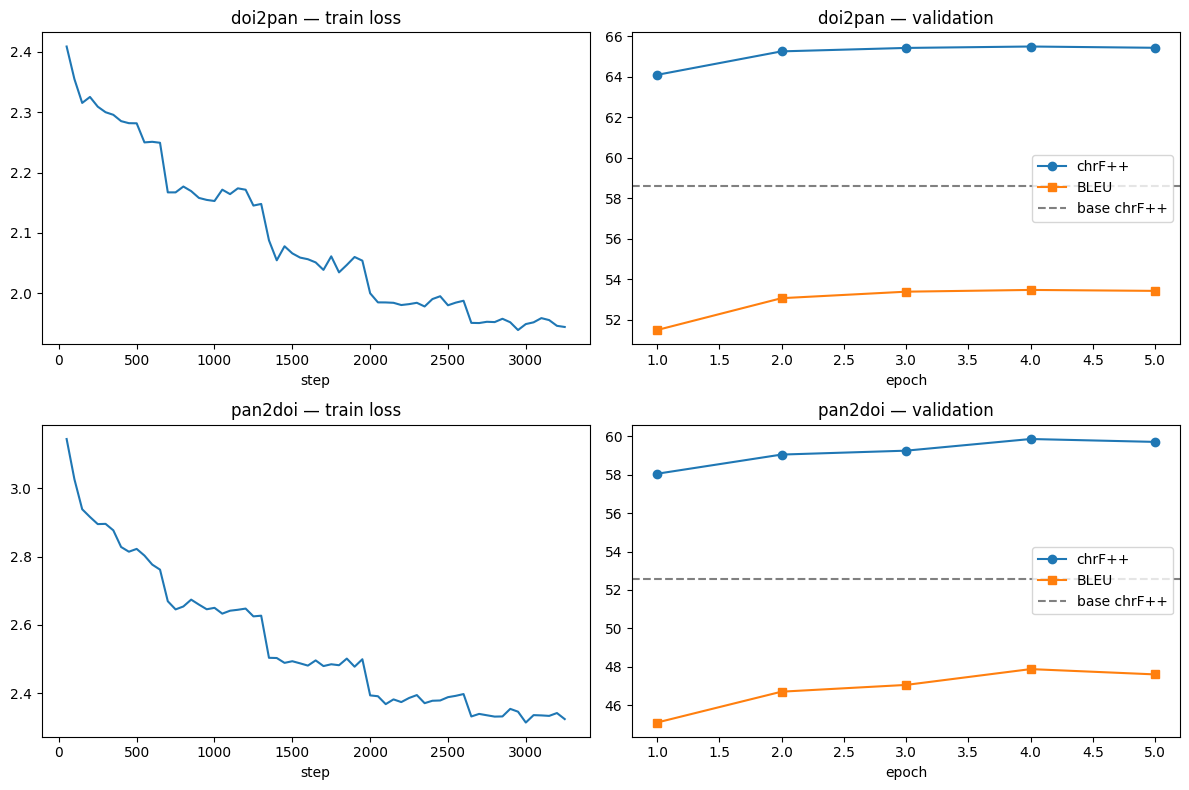

In [10]:
# =============================================================================
# CELL 10 — TRAINING / VALIDATION CURVES
# =============================================================================
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(DIRECTIONS), 2, figsize=(12, 4 * len(DIRECTIONS)))
for r, d in enumerate(DIRECTIONS):
    out_dir = RESULT[d]["out_dir"]
    logs = json.load(open(os.path.join(out_dir, "log_history.json")))
    tr = [(l["step"], l["loss"]) for l in logs if "loss" in l]
    if tr:
        axes[r][0].plot(*zip(*tr)); axes[r][0].set_title(f"{d} — train loss"); axes[r][0].set_xlabel("step")
    vh = json.load(open(os.path.join(out_dir, "val_history.json")))
    axes[r][1].plot([v["epoch"] for v in vh], [v["chrf"] for v in vh], marker="o", label="chrF++")
    axes[r][1].plot([v["epoch"] for v in vh], [v["bleu"] for v in vh], marker="s", label="BLEU")
    axes[r][1].axhline(BASE_VAL[d]["chrf"], ls="--", c="gray", label="base chrF++")
    axes[r][1].set_title(f"{d} — validation"); axes[r][1].set_xlabel("epoch"); axes[r][1].legend()
plt.tight_layout(); plt.savefig(RESULTS_DIR / "training_curves.png", dpi=120); plt.show()

In [11]:
# =============================================================================
# CELL 11 — FINAL TEST  (the ONLY time the test set is used)
# =============================================================================
rows = []
for d in DIRECTIONS:
    info = direction_data[d]
    test = info["test"]
    srcs, refs = test["src_text"].tolist(), test["tgt_text"].tolist()

    m = load_with_adapter(RESULT[d]["best_dir"])
    preds = translate(m, srcs, info["src_lang"], info["tgt_lang"],
                      num_beams=TEST_BEAMS, length_penalty=TEST_LENGTH_PENALTY)
    rows.append({"direction": d, "model": "Fine-tuned (LoRA, 1B)", "N": len(refs), **score(preds, refs)})
    pd.DataFrame({"src": srcs, "ref": refs, "pred": preds}).to_csv(RESULTS_DIR / f"{d}_test_predictions.csv", index=False)
    shutil.copytree(RESULT[d]["best_dir"], FINAL_DIR / d, dirs_exist_ok=True)
    del m; gc.collect(); torch.cuda.empty_cache()

base = load_base().eval()
for d in DIRECTIONS:
    info = direction_data[d]
    test = info["test"]
    preds = translate(base, test["src_text"].tolist(), info["src_lang"], info["tgt_lang"],
                      num_beams=TEST_BEAMS, length_penalty=TEST_LENGTH_PENALTY)
    rows.append({"direction": d, "model": "Base IndicTrans2-1B", "N": len(test),
                 **score(preds, test["tgt_text"].tolist())})
del base; gc.collect(); torch.cuda.empty_cache()

final_df = pd.DataFrame(rows).sort_values(["direction", "model"]).reset_index(drop=True)
final_df.to_csv(RESULTS_DIR / "FINAL_dogpun_test_results.csv", index=False)

print("=" * 90 + "\nFINAL TEST RESULTS — DOGRI <-> PUNJABI (IndicTrans2-1B + LoRA)\n" + "=" * 90)
display(final_df.round(2))

print("\nGain over base model:")
for d in DIRECTIONS:
    f = final_df[(final_df.direction == d) & final_df.model.str.startswith("Fine")].iloc[0]
    b = final_df[(final_df.direction == d) & final_df.model.str.startswith("Base")].iloc[0]
    print(f"  {d}: BLEU {f['BLEU']-b['BLEU']:+.2f} | chrF++ {f['chrF++']-b['chrF++']:+.2f}")
print("\nAdapters to submit / reuse:", FINAL_DIR)

doi->pan:   0%|          | 0/73 [00:00<?, ?it/s]

pan->doi:   0%|          | 0/73 [00:00<?, ?it/s]

doi->pan:   0%|          | 0/73 [00:00<?, ?it/s]

pan->doi:   0%|          | 0/73 [00:00<?, ?it/s]

FINAL TEST RESULTS — DOGRI <-> PUNJABI (IndicTrans2-1B + LoRA)


,direction,model,N,BLEU,chrF++
0,doi2pan,Base IndicTrans2-1B,1158,45.30,58.71
1,doi2pan,"Fine-tuned (LoRA, 1B)",1158,52.93,65.15
2,pan2doi,Base IndicTrans2-1B,1158,38.80,52.63
3,pan2doi,"Fine-tuned (LoRA, 1B)",1158,46.38,58.75



Gain over base model:
  doi2pan: BLEU +7.63 | chrF++ +6.45
  pan2doi: BLEU +7.58 | chrF++ +6.12

Adapters to submit / reuse: /kaggle/working/dogpun_indictrans2/final_adapters
